# Modelagem Supervisionada, Validação Cruzada e Otimização
### Projeto Final SME0828 — Diagnóstico de Câncer de Mama (WDBC) — ICMC-USP — Prof. Francisco Rodrigues

**Responsável por esta etapa:** Vitor Dias Ferreira

## Objetivo

Treinar e ajustar os classificadores supervisionados do projeto e deixar os modelos prontos para a avaliação final no conjunto de teste:

1. Sete modelos: Regressão Logística (L1/L2), KNN, SVM linear, SVM RBF, Naive Bayes Gaussiano, Árvore de Decisão e Random Forest.
2. Validação cruzada estratificada (`StratifiedKFold`, 10 folds) no conjunto de treino.
3. Busca de hiperparâmetros com `GridSearchCV` para cada modelo.
4. Comparação em quatro cenários. A, B e C são os do planejamento; D é uma segunda versão do cenário C do planejamento ("apenas o subconjunto das features selecionadas"), com a seleção feita em `Feature_selection.ipynb`:
   - **Cenário A:** os 30 atributos originais padronizados;
   - **Cenário B:** componentes do PCA que mantêm 90% ou 95% da variância (a escolha é feita na validação cruzada);
   - **Cenário C:** só os *k* atributos mais informativos (`SelectKBest`), com *k* escolhido na própria validação cruzada;
   - **Cenário D:** só os 10 atributos do Top-10 não redundante de `Feature_selection.ipynb`.
5. **Entregas:** tabela com os melhores hiperparâmetros de cada classificador e os modelos ajustados, salvos para a avaliação final.

Cada seção segue o padrão: **markdown com o plano** → **código** → **markdown com a interpretação do resultado**.

### Observações sobre as etapas anteriores

- **Divisão treino/teste:** uso exatamente a divisão preparada em `analise.ipynb` e usada em `Feature_selection.ipynb` (`test_size=0.2`, `stratify=y`, `random_state=42`). A Seção 1 confere que ela é a mesma dos arquivos gerados por `Feature_selection.ipynb`. **O conjunto de teste não é usado em nenhum momento deste notebook.** A avaliação no teste é a etapa seguinte do projeto, e olhar o teste aqui contaminaria a escolha dos modelos.
- **Arquivos de `Feature_selection.ipynb`** (`X_train_scaled.csv`, `wdbc_train_pca.csv`, `wdbc_train_top10.csv` e as versões de teste): o padronizador, o PCA e a seleção desse notebook são ajustados só no treino, e a coluna `id` não entra nos atributos, então os arquivos estão corretos. Mesmo assim, os modelos daqui não são treinados direto nesses CSVs já transformados. O padronizador, o PCA e a seleção ficam **dentro do pipeline** e são reajustados no treino de cada fold. O motivo é a validação cruzada: os arquivos foram transformados com os 455 pacientes do treino, e dentro da validação cruzada os folds de validação já teriam participado desse ajuste. Esses arquivos entram assim:
  - **cenário A** corresponde a `X_train_scaled.csv` (mesma padronização, refeita em cada fold);
  - **cenário B com 90% da variância** corresponde a `wdbc_train_pca.csv` (a Seção 3.1 confere que dá os mesmos 7 componentes);
  - **cenário D** usa a lista de atributos de `wdbc_train_top10.csv`, lida do cabeçalho do arquivo.
- **Consequência para a avaliação final:** os modelos salvos recebem os **30 atributos originais, sem padronizar** (`wdbc_limpo.csv` com a mesma divisão), porque cada pipeline faz a sua própria padronização, PCA ou seleção. Passar `X_test_scaled.csv` ou `wdbc_test_*.csv` para eles padronizaria os dados duas vezes (detalhes na Seção 5).

## 0. Preparação do ambiente

Bibliotecas de dados, gráficos e `scikit-learn`, semente fixa para reprodutibilidade, versões impressas (para quem rodar depois conseguir reproduzir) e o tema escuro dos gráficos.

In [1]:
import warnings

import platform
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import get_scorer, make_scorer, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Avisos de obsolescência silenciados (as versões ficam registradas abaixo; os demais avisos continuam aparecendo):
# - SVC(probability=True) está obsoleto desde o scikit-learn 1.9 (sai na 1.11);
# - LogisticRegression(penalty=...) está obsoleto desde a 1.8 (sai na 1.10). Ele é mantido porque o substituto,
#   l1_ratio, não funciona antes da 1.8 (por exemplo, no Colab): lá l1_ratio=1 seria ignorado e o modelo viraria L2.
warnings.filterwarnings("ignore", message=".*`probability` parameter was deprecated.*", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*'penalty' was deprecated.*", category=FutureWarning)
warnings.filterwarnings("ignore", message="Inconsistent values: penalty=", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 200)

# Tema escuro para os gráficos
plt.style.use("dark_background")
sns.set_theme(style="darkgrid", rc={
    "axes.facecolor": "#1e1e1e", "figure.facecolor": "#121212", "grid.color": "#333333",
    "text.color": "white", "axes.labelcolor": "white", "xtick.color": "white",
    "ytick.color": "white", "axes.edgecolor": "white",
})
PALETA = "viridis"

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_DADOS = BASE_DIR / "data" / "processed"
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")

Python 3.14.4 | pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1


## 1. Dados e divisão treino/teste

**Plano:** carregar `data/processed/wdbc_limpo.csv` (gerado em `analise.ipynb`), separar `X` com os 30 atributos numéricos (sem `id`) e `y = diagnosis` (0 = benigno, 1 = maligno), repetir exatamente a divisão estratificada 80/20 de `analise.ipynb` e conferir que ela é a mesma dos arquivos de treino de `Feature_selection.ipynb`.

In [2]:
df = pd.read_csv(PASTA_DADOS / "wdbc_limpo.csv")
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"]
assert X.shape == (569, 30) and set(y.unique()) == {0, 1}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Conferência com os arquivos de treino de Feature_selection.ipynb (só o treino: o teste não é aberto aqui)
assert (pd.read_csv(PASTA_DADOS / "y_train.csv")["diagnosis"].values == y_train.values).all()
assert np.allclose(pd.read_csv(PASTA_DADOS / "X_train_scaled.csv")[X.columns].values,
                   StandardScaler().fit_transform(X_train))
print("Treino:", X_train.shape, "| Teste:", X_test.shape, "(o teste fica guardado para a avaliação final)")
print("Divisão conferida: mesmos pacientes, na mesma ordem, de X_train_scaled.csv e y_train.csv (Feature_selection.ipynb).")
display(pd.DataFrame({"treino": y_train.value_counts(), "teste": y_test.value_counts(),
                      "proporção no treino": y_train.value_counts(normalize=True).round(3)})
        .rename(index={0: "Benigno (0)", 1: "Maligno (1)"}))

Treino: (455, 30) | Teste: (114, 30) (o teste fica guardado para a avaliação final)
Divisão conferida: mesmos pacientes, na mesma ordem, de X_train_scaled.csv e y_train.csv (Feature_selection.ipynb).


,treino,teste,proporção no treino
diagnosis,,,
Benigno (0),285,72,0.626
Maligno (1),170,42,0.374


**Como interpretar:** 455 pacientes no treino (285 benignos e 170 malignos, 37,4% malignos) e 114 no teste (72 e 42), com a mesma proporção nos dois. É a mesma divisão de `analise.ipynb` e a mesma usada em `Feature_selection.ipynb`: os `assert` acima conferem que os arquivos `y_train.csv` e `X_train_scaled.csv` têm os mesmos pacientes, na mesma ordem. Assim, a avaliação final consegue recriar exatamente o mesmo teste. Com 10 folds, cada fold de validação tem cerca de 46 pacientes, sendo só uns 17 malignos. Isso importa na leitura da sensibilidade: errar um único caso maligno num fold já tira 6 pontos percentuais.

## 2. Cenários, modelos e grades de hiperparâmetros

**Plano:** todo cenário usa `StandardScaler`, ajustado só no treino de cada fold. Ele é necessário para Regressão Logística, KNN e SVM e para o PCA, e é inofensivo para Naive Bayes e para as árvores, que ficam no mesmo esquema para que a comparação seja justa.

| Cenário | Pipeline | Arquivo correspondente de `Feature_selection.ipynb` |
|---|---|---|
| A | `StandardScaler` → modelo | `X_train_scaled.csv` |
| B | `StandardScaler` → `PCA` → modelo, com a variância mantida (90% ou 95%) buscada junto com os hiperparâmetros | `wdbc_train_pca.csv` (90%) |
| C | `StandardScaler` → `SelectKBest(f_classif, k)` → modelo, com *k* ∈ {5, 10, 15, 20, 25} buscado junto com os hiperparâmetros | nenhum (seleção feita aqui) |
| D | 10 atributos do Top-10 não redundante → `StandardScaler` → modelo | `wdbc_train_top10.csv` |

- **B:** o planejamento sugere 95% da variância e `Feature_selection.ipynb` exportou 90%. Em vez de escolher um dos dois, deixo a validação cruzada decidir, como no *k* do cenário C.
- **C:** o teste F da ANOVA (`f_classif`) foi escolhido porque é determinístico e rápido. A informação mútua, usada em `Feature_selection.ipynb`, tem componente aleatória e deixaria a busca bem mais lenta.
- **D:** o Top-10 de `Feature_selection.ipynb` são os 10 atributos de maior informação mútua entre os **não redundantes** (nenhum par com |r| > 0,85). A lista é lida do cabeçalho de `wdbc_train_top10.csv`, então acompanha esse arquivo. Diferente de C, a escolha dos atributos não é refeita em cada fold: ela foi feita uma vez com os 455 pacientes do treino, inclusive os que caem nos folds de validação, o que pode deixar a validação cruzada de D um pouco otimista. A Seção 3.2 mede esse efeito. O teste continua intocado.

**Métrica da busca:** ROC-AUC, que não depende de limiar e mede a capacidade de separar benignos de malignos. Também registramos, para o melhor ponto de cada busca, **sensibilidade** (malignos detectados), **especificidade** (benignos corretamente descartados), precisão, F1 e acurácia. A sensibilidade é a métrica clínica mais importante (um falso negativo é um câncer que passou despercebido), mas otimizar só por ela favorece modelos que chamam tudo de maligno. O ajuste do limiar para reduzir falsos negativos fica para a avaliação final, que recebe modelos com `predict_proba`.

**Validação cruzada:** `StratifiedKFold` com 10 folds, embaralhado e com semente fixa, os mesmos folds para todos os modelos e cenários.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
METRICAS = {
    "ROC-AUC": "roc_auc",
    "Sensibilidade": "recall",
    "Especificidade": make_scorer(recall_score, pos_label=0),
    # zero_division=0: se um modelo não prevê nenhum maligno num fold, a precisão vale 0 (sem aviso a cada fold)
    "Precisão": make_scorer(precision_score, zero_division=0),
    "F1": "f1",
    "Acurácia": "accuracy",
}

MODELOS = {
    # penalty funciona em todas as versões até a 1.9 (ver o comentário da Seção 0 sobre l1_ratio)
    "Regressão Logística": (
        LogisticRegression(max_iter=5000, solver="liblinear", random_state=RANDOM_STATE),
        {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100], "modelo__penalty": ["l1", "l2"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"modelo__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "modelo__weights": ["uniform", "distance"],
         "modelo__metric": ["euclidean", "manhattan"]}),
    "SVM Linear": (
        SVC(kernel="linear", probability=True, random_state=RANDOM_STATE),
        {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100]}),
    "SVM RBF": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"modelo__C": [0.1, 1, 10, 100, 1000], "modelo__gamma": ["scale", 0.001, 0.01, 0.1, 1]}),
    "Naive Bayes Gaussiano": (
        GaussianNB(),
        {"modelo__var_smoothing": np.logspace(-12, -2, 11)}),
    "Árvore de Decisão": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"modelo__max_depth": [2, 3, 4, 5, 6, 8, None], "modelo__min_samples_leaf": [1, 2, 5, 10],
         "modelo__criterion": ["gini", "entropy"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"modelo__n_estimators": [200, 500], "modelo__max_depth": [None, 4, 8],
         "modelo__max_features": ["sqrt", 0.3], "modelo__min_samples_leaf": [1, 3]}),
}

# Cenário D: atributos do Top-10 de Feature_selection.ipynb, lidos do cabeçalho do arquivo
TOP10_SELECAO = list(pd.read_csv(PASTA_DADOS / "wdbc_train_top10.csv", nrows=0).columns)
assert len(TOP10_SELECAO) == 10 and set(TOP10_SELECAO) <= set(X.columns)


def montar_pipeline(cenario, estimador):
    passos = []
    if cenario == "D":
        # O pipeline recebe os 30 atributos originais e mantém só as colunas do Top-10
        passos.append(("top10_selecao", ColumnTransformer([("top10", "passthrough", TOP10_SELECAO)])))
    passos.append(("escala", StandardScaler()))
    if cenario == "B":
        passos.append(("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)))
    elif cenario == "C":
        passos.append(("selecao", SelectKBest(score_func=f_classif)))
    passos.append(("modelo", clone(estimador)))
    return Pipeline(passos)


CENARIOS = {"A": "30 atributos padronizados", "B": "PCA (90% ou 95% da variância)", "C": "SelectKBest (top-k)",
            "D": "Top-10 não redundante"}
print(f"{len(MODELOS)} modelos × {len(CENARIOS)} cenários = {len(MODELOS) * len(CENARIOS)} buscas de hiperparâmetros")
print("Top-10 não redundante (Feature_selection.ipynb):", TOP10_SELECAO)

7 modelos × 4 cenários = 28 buscas de hiperparâmetros
Top-10 não redundante (Feature_selection.ipynb): ['radius_worst', 'concave_points_mean', 'area_se', 'concavity_worst', 'compactness_mean', 'texture_worst', 'concave_points_se', 'symmetry_worst', 'smoothness_mean', 'smoothness_worst']


## 3. Busca de hiperparâmetros (`GridSearchCV`)

**Plano:** para cada modelo e cenário (28 buscas), rodar o `GridSearchCV` no treino com os 10 folds, escolher a combinação de maior ROC-AUC (`refit="ROC-AUC"`) e guardar o pipeline reajustado no treino inteiro.

In [4]:
buscas, linhas = {}, []
inicio = time.perf_counter()
for nome, (estimador, grade) in MODELOS.items():
    for cenario in CENARIOS:
        grade_cenario = dict(grade)
        if cenario == "B":
            grade_cenario["pca__n_components"] = [0.90, 0.95]
        elif cenario == "C":
            grade_cenario["selecao__k"] = [5, 10, 15, 20, 25]
        busca = GridSearchCV(montar_pipeline(cenario, estimador), grade_cenario, cv=cv, scoring=METRICAS,
                             refit="ROC-AUC", n_jobs=-1)
        busca.fit(X_train, y_train)
        buscas[(nome, cenario)] = busca
        i = busca.best_index_
        linha = {"modelo": nome, "cenário": cenario}
        for metrica in METRICAS:
            linha[metrica] = busca.cv_results_[f"mean_test_{metrica}"][i]
            linha[f"{metrica}_dp"] = busca.cv_results_[f"std_test_{metrica}"][i]
        linha["melhores_hiperparametros"] = {k.split("__")[1]: (round(float(v), 14) if isinstance(v, (float, np.floating)) else v)
                                             for k, v in busca.best_params_.items()}
        linhas.append(linha)
print(f"{len(buscas)} buscas concluídas em {time.perf_counter() - inicio:.0f} s")

resultados = pd.DataFrame(linhas).set_index(["modelo", "cenário"])
tabela_hiper = resultados[["melhores_hiperparametros", "ROC-AUC", "Sensibilidade", "Especificidade"]]
print("=== Melhores hiperparâmetros (validação cruzada com 10 folds no treino) ===")
display(tabela_hiper.style.format({"ROC-AUC": "{:.4f}", "Sensibilidade": "{:.3f}", "Especificidade": "{:.3f}"}))

28 buscas concluídas em 266 s
=== Melhores hiperparâmetros (validação cruzada com 10 folds no treino) ===


**Como interpretar:**
- **Regressão Logística:** penalidade L2 em todos os cenários, com `C = 1` em A e B e `C = 10` em C e D. A regularização moderada basta, porque o problema é quase linearmente separável.
- **KNN:** distância euclidiana com peso pela distância em todos os cenários. O número de vizinhos varia muito (31 no A, 5 no B e no D, 15 no C): com menos dimensões, vizinhos próximos ficam mais informativos.
- **SVM Linear:** `C = 1` em A, B e C, e `C = 10` em D.
- **SVM RBF:** `C = 10` com `gamma = 0.01` (A e B) ou `gamma = "scale"` (C), e `C = 100` com `gamma = 0.01` em D. Um `gamma` pequeno dá uma fronteira suave, quase linear.
- **Naive Bayes Gaussiano:** `var_smoothing` mínimo em A e D (o modelo não precisa de suavização) e 0,01 em B e C.
- **Árvore de Decisão:** árvores rasas (profundidade 3 a 6) com pelo menos 5 a 10 pacientes por folha, porque árvores maiores decoram o treino.
- **Random Forest:** árvores sem limite de profundidade em todos os cenários, com 500 árvores em A, B e C e 200 em D. O aleatório das árvores e a média entre elas já controlam o sobreajuste.
- **Variância do PCA (cenário B):** 95% em cinco modelos; só Naive Bayes e Árvore de Decisão ficaram com 90%.

Alguns valores ficaram na borda da grade: 500 árvores no Random Forest, *k* = 25 no cenário C, 31 vizinhos no KNN (A), `var_smoothing` nos dois extremos e 10 pacientes por folha na árvore (B e C). Mais árvores só estabilizam a floresta, e *k* = 30 seria o próprio cenário A. Para os outros casos, testei à parte grades maiores (até 71 vizinhos, `var_smoothing` até 1 e até 30 pacientes por folha): a ROC-AUC subiu no máximo 0,004 (Naive Bayes B), sem mudar a ordem dos modelos, então as grades foram mantidas.

=== Desempenho na validação cruzada (média ± desvio-padrão nos 10 folds), no melhor ponto de cada busca ===


ROC-AUC  Sensibilidade Especificidade  \
modelo                cenário                                                
Regressão Logística   A        0.995 ± 0.008  0.959 ± 0.046  0.986 ± 0.023   
                      B        0.994 ± 0.011  0.959 ± 0.046  0.990 ± 0.022   
                      C        0.995 ± 0.007  0.947 ± 0.049  0.979 ± 0.023   
                      D        0.997 ± 0.005  0.935 ± 0.061  0.983 ± 0.023   
KNN                   A        0.990 ± 0.016  0.888 ± 0.085  0.993 ± 0.014   
                      B        0.989 ± 0.021  0.929 ± 0.086  0.990 ± 0.016   
                      C        0.992 ± 0.016  0.918 ± 0.088  0.993 ± 0.014   
                      D        0.994 ± 0.013  0.912 ± 0.088  0.986 ± 0.017   
SVM Linear            A        0.993 ± 0.008  0.941 ± 0.059  0.983 ± 0.023   
                      B        0.994 ± 0.010  0.953 ± 0.051  0.986 ± 0.023   
                      C        0.995 ± 0.009  0.959 ± 0.053  0.983 ± 0.023   
                      D        0.995 ± 0.006  0.941 ± 0.064  0.975 ± 0.022   
SVM RBF               A        0.996 ± 0.009  0.953 ± 0.058  0.983 ± 0.028   
                      B        0.996 ± 0.008  0.941 ± 0.064  0.986 ± 0.023   
                      C        0.996 ± 0.008  0.959 ± 0.053  0.983 ± 0.023   
                      D        0.997 ± 0.005  0.935 ± 0.061  0.990 ± 0.016   
Naive Bayes Gaussiano A        0.986 ± 0.014  0.900 ± 0.075  0.958 ± 0.038   
                      B        0.974 ± 0.022  0.847 ± 0.075  0.972 ± 0.038   
                      C        0.986 ± 0.017  0.918 ± 0.080  0.954 ± 0.036   
                      D        0.981 ± 0.017  0.912 ± 0.080  0.958 ± 0.042   
Árvore de Decisão     A        0.960 ± 0.031  0.876 ± 0.100  0.954 ± 0.039   
                      B        0.970 ± 0.026  0.882 ± 0.064  0.965 ± 0.022   
                      C        0.971 ± 0.034  0.876 ± 0.089  0.958 ± 0.038   
                      D        0.980 ± 0.026  0.935 ± 0.081  0.975 ± 0.016   
Random Forest         A        0.990 ± 0.012  0.935 ± 0.067  0.975 ± 0.027   
                      B        0.988 ± 0.015  0.924 ± 0.079  0.972 ± 0.031   
                      C        0.990 ± 0.013  0.935 ± 0.067  0.979 ± 0.024   
                      D        0.994 ± 0.008  0.935 ± 0.067  0.979 ± 0.028   

                                    Precisão             F1       Acurácia  
modelo                cenário                                               
Regressão Logística   A        0.977 ± 0.037  0.967 ± 0.031  0.976 ± 0.023  
                      B        0.982 ± 0.038  0.970 ± 0.038  0.978 ± 0.028  
                      C        0.965 ± 0.039  0.955 ± 0.036  0.967 ± 0.026  
                      D        0.971 ± 0.037  0.951 ± 0.034  0.965 ± 0.024  
KNN                   A        0.987 ± 0.026  0.933 ± 0.050  0.954 ± 0.033  
                      B        0.980 ± 0.031  0.953 ± 0.059  0.967 ± 0.040  
                      C        0.987 ± 0.026  0.949 ± 0.052  0.965 ± 0.036  
                      D        0.975 ± 0.031  0.940 ± 0.053  0.958 ± 0.035  
SVM Linear            A        0.971 ± 0.038  0.955 ± 0.037  0.967 ± 0.026  
                      B        0.977 ± 0.038  0.964 ± 0.035  0.974 ± 0.025  
                      C        0.971 ± 0.039  0.964 ± 0.037  0.974 ± 0.027  
                      D        0.961 ± 0.035  0.949 ± 0.029  0.963 ± 0.020  
SVM RBF               A        0.973 ± 0.043  0.961 ± 0.028  0.971 ± 0.020  
                      B        0.978 ± 0.036  0.957 ± 0.035  0.969 ± 0.024  
                      C        0.972 ± 0.037  0.964 ± 0.030  0.974 ± 0.021  
                      D        0.982 ± 0.028  0.957 ± 0.040  0.969 ± 0.028  
Naive Bayes Gaussiano A        0.931 ± 0.060  0.913 ± 0.050  0.936 ± 0.036  
                      B        0.952 ± 0.061  0.894 ± 0.049  0.925 ± 0.033  
                      C        0.925 ± 0.055  0.919 ± 0.056  0.941 ± 0.041  
                      D        0.932 ± 0.061  0.919 ± 0.053  0.940 ± 0.039  
Ár

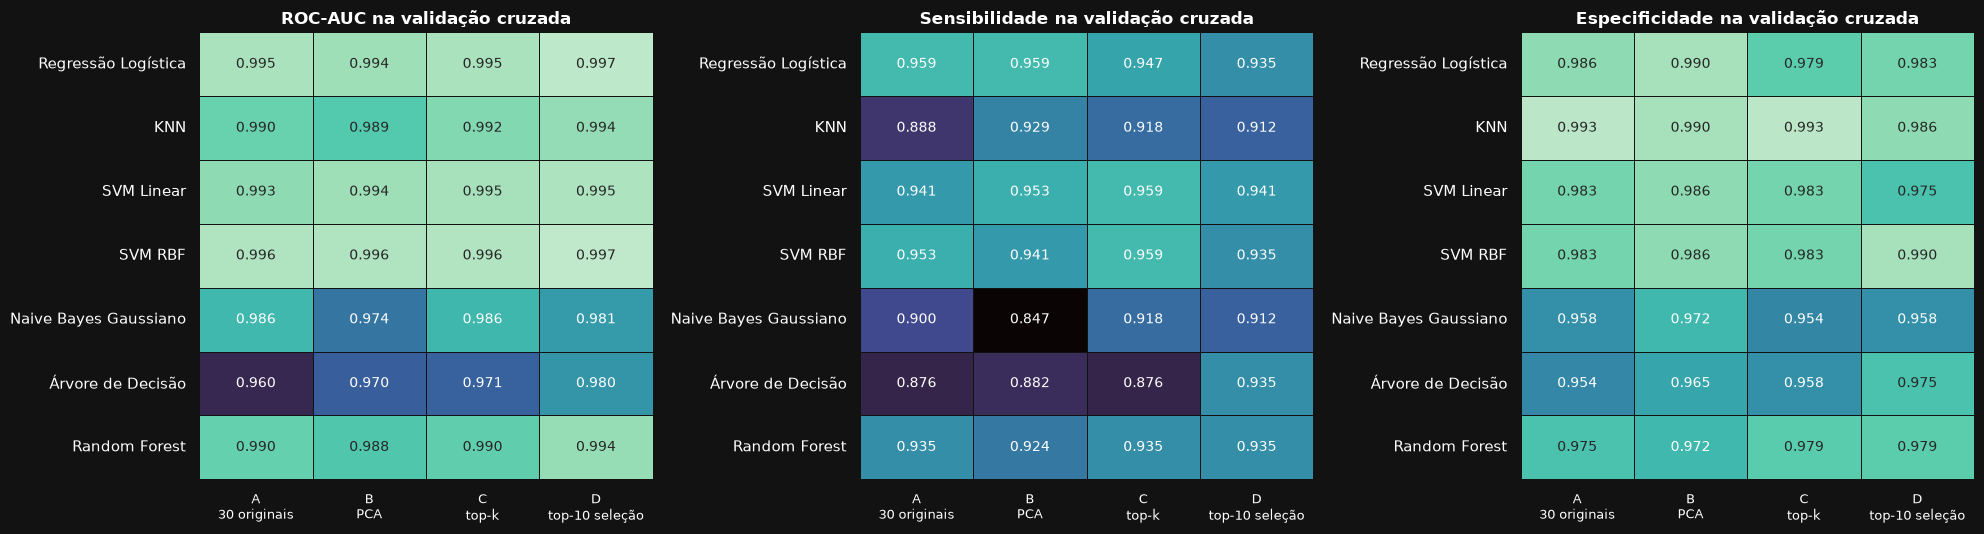

In [5]:
media_dp = lambda m: resultados[m].map("{:.3f}".format) + " ± " + resultados[f"{m}_dp"].map("{:.3f}".format)
tabela_cv = pd.DataFrame({m: media_dp(m) for m in METRICAS})
print("=== Desempenho na validação cruzada (média ± desvio-padrão nos 10 folds), no melhor ponto de cada busca ===")
display(tabela_cv)

ROTULOS_CENARIOS = {"A": "30 originais", "B": "PCA", "C": "top-k", "D": "top-10 seleção"}
fig, eixos = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, metrica, faixa in zip(eixos, ["ROC-AUC", "Sensibilidade", "Especificidade"], [(0.95, 1.0), (0.85, 1.0), (0.9, 1.0)]):
    mapa = resultados[metrica].unstack("cenário").loc[list(MODELOS)]
    sns.heatmap(mapa, annot=True, fmt=".3f", cmap="mako", vmin=faixa[0], vmax=faixa[1], linewidths=0.5,
                linecolor="#121212", cbar=False, annot_kws={"fontsize": 10}, ax=ax)
    ax.set_title(f"{metrica} na validação cruzada", color="white", fontweight="bold")
    ax.set_xticklabels([f"{c}\n{ROTULOS_CENARIOS[c]}" for c in mapa.columns], rotation=0, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Como interpretar:**
- **Todos os modelos separam muito bem as classes:** ROC-AUC entre 0,960 e 0,997. A base é conhecida por ser quase separável com essas medidas, como `Feature_selection.ipynb` já tinha mostrado no PCA e no t-SNE.
- **O grupo de cima** é formado por Regressão Logística, SVM Linear e SVM RBF, com ROC-AUC de 0,993 a 0,997, sensibilidade de 0,935 a 0,959 e especificidade de 0,975 a 0,990. Por exemplo, a Regressão Logística no cenário A detecta 95,9% dos malignos e descarta corretamente 98,6% dos benignos.
- **O cenário D (Top-10 não redundante) tem a maior ROC-AUC em seis dos sete modelos**; só o Naive Bayes fica melhor no A. Há duas ressalvas:
  - a lista de D foi escolhida com todo o treino, e a Seção 3.2 mede quanto dessa vantagem é otimismo;
  - na Regressão Logística e no SVM RBF, a sensibilidade de D cai para 0,935 (contra 0,959 e 0,953 no A). A ROC-AUC mede a ordenação dos pacientes, e a sensibilidade depende do limiar de 0,5, que ainda será ajustado na avaliação final.
- **Random Forest e KNN** ficam logo abaixo (ROC-AUC de 0,988 a 0,994). O KNN no cenário A é o mais "cauteloso para o lado errado": alta especificidade (0,993), mas uma das menores sensibilidades da tabela (0,888).
- **Naive Bayes e Árvore de Decisão** são os mais fracos, com ROC-AUC de 0,960 a 0,986 e sensibilidade de 0,85 a 0,94. A árvore perde por ser um modelo único e instável, e o Naive Bayes por supor independência entre atributos que são muito correlacionados (raio, perímetro e área medem quase a mesma coisa).
- **Os desvios-padrão da sensibilidade são grandes** (±0,05 a ±0,10) pelo motivo da Seção 1: cada fold tem só uns 17 malignos. Por isso a comparação da Seção 4 usa validação cruzada repetida e teste estatístico em vez de olhar a terceira casa decimal.

### 3.1 O que os cenários B, C e D fizeram com os dados

**Plano:** ajustar no treino inteiro o PCA do cenário B com 90% e com 95% da variância, para ver quantos componentes cada um mantém e conferir que o de 90% reproduz o `wdbc_train_pca.csv` de `Feature_selection.ipynb`. Depois, ver o *k* que cada modelo escolheu no cenário C e comparar o top-10 do teste F (cenário C com *k* = 10) com o Top-10 não redundante (cenário D).

In [6]:
for variancia in [0.90, 0.95]:
    pca = Pipeline([("escala", StandardScaler()),
                    ("pca", PCA(n_components=variancia, random_state=RANDOM_STATE))]).fit(X_train)
    print(f"Cenário B com {variancia:.0%}: o PCA ajustado no treino mantém {pca.named_steps['pca'].n_components_} "
          f"componentes ({pca.named_steps['pca'].explained_variance_ratio_.sum():.1%} da variância).")
    if variancia == 0.90:
        pca_arquivo = pd.read_csv(PASTA_DADOS / "wdbc_train_pca.csv")
        # cada componente do PCA só é definida a menos do sinal, por isso a comparação é em valor absoluto
        assert np.allclose(np.abs(pca_arquivo.values), np.abs(pca.transform(X_train)))
        print(f"   -> mesmos valores do wdbc_train_pca.csv de Feature_selection.ipynb ({pca_arquivo.shape[1]} componentes).")
variancias = resultados.xs("B", level="cenário")["melhores_hiperparametros"].map(lambda p: f"{p['n_components']:.0%}")
print("\nCenário B: variância escolhida em cada modelo:", variancias.to_dict())

ks = resultados.xs("C", level="cenário")["melhores_hiperparametros"].map(lambda p: p["k"])
print("\nCenário C: k escolhido em cada modelo:", ks.to_dict())

selecao = SelectKBest(f_classif, k=10).fit(StandardScaler().fit_transform(X_train), y_train)
top10_aqui = list(X_train.columns[np.argsort(-selecao.scores_)[:10]])
maior_r = lambda atributos: (X_train[atributos].corr().abs().values - np.eye(len(atributos))).max()
print("\nTop-10 pelo teste F (cenário C com k = 10):", top10_aqui)
print("Top-10 não redundante (cenário D):         ", TOP10_SELECAO)
print("Em comum:", len(set(top10_aqui) & set(TOP10_SELECAO)), "de 10 ->", sorted(set(top10_aqui) & set(TOP10_SELECAO)))
print(f"Maior |r| entre dois atributos da lista: teste F = {maior_r(top10_aqui):.3f} | não redundante = {maior_r(TOP10_SELECAO):.3f}")

Cenário B com 90%: o PCA ajustado no treino mantém 7 componentes (91.1% da variância).
   -> mesmos valores do wdbc_train_pca.csv de Feature_selection.ipynb (7 componentes).
Cenário B com 95%: o PCA ajustado no treino mantém 10 componentes (95.2% da variância).

Cenário B: variância escolhida em cada modelo: {'Regressão Logística': '95%', 'KNN': '95%', 'SVM Linear': '95%', 'SVM RBF': '95%', 'Naive Bayes Gaussiano': '90%', 'Árvore de Decisão': '90%', 'Random Forest': '95%'}

Cenário C: k escolhido em cada modelo: {'Regressão Logística': 25, 'KNN': 20, 'SVM Linear': 25, 'SVM RBF': 25, 'Naive Bayes Gaussiano': 5, 'Árvore de Decisão': 5, 'Random Forest': 20}

Top-10 pelo teste F (cenário C com k = 10): ['concave_points_worst', 'perimeter_worst', 'radius_worst', 'concave_points_mean', 'perimeter_mean', 'area_worst', 'radius_mean', 'area_mean', 'concavity_mean', 'concavity_worst']
Top-10 não redundante (cenário D):          ['radius_worst', 'concave_points_mean', 'area_se', 'concavity_worst'

**Como interpretar:**
- **Cenário B:** ajustado só no treino, o PCA mantém **7 componentes** para 90% da variância (exatamente os valores do `wdbc_train_pca.csv`) e **10 componentes** para 95%. Nos dois casos, 30 atributos viram 7 a 10, uma redução grande, coerente com a forte redundância entre as medidas.
- **Cenário C:** os modelos lineares e o SVM RBF escolheram manter **25 dos 30 atributos**, KNN e Random Forest 20, e só Naive Bayes e Árvore de Decisão preferiram **5**. Para os melhores modelos, a seleção pelo teste F não ajuda a prever melhor; eles usam quase tudo. Para Naive Bayes e árvore, poucos atributos fortes são melhores do que muitos redundantes.
- **C × D:** os dois top-10 têm só **3 atributos em comum** (`radius_worst`, `concave_points_mean` e `concavity_worst`). O top-10 do teste F é quase todo de medidas de tamanho e de concavidade que repetem a mesma informação (maior |r| = 0,998, entre `radius_mean` e `perimeter_mean`). O Top-10 não redundante troca parte desse poder individual por atributos não redundantes (maior |r| = 0,846), incluindo textura, simetria e suavidade. Mesmo assim, a Seção 3 mostrou que D tem ROC-AUC igual ou maior que a do cenário A na maioria dos modelos: a informação dos 30 atributos cabe em 10 bem escolhidos.

### 3.2 Quanto a lista fixa favorece o cenário D

**Plano:** a lista do cenário D foi escolhida uma vez, com todo o treino. Para medir quanto isso favorece D na validação cruzada, refaço a regra de `Feature_selection.ipynb` (informação mútua com o diagnóstico + filtro de colinearidade com |r| ≤ 0,85) **dentro de cada um dos 10 folds**, usando só o treino do fold, e comparo:
1. em quantos folds cada atributo é escolhido;
2. a ROC-AUC de cada modelo com a lista fixa (busca da Seção 3) e com a lista refeita em cada fold, com os mesmos hiperparâmetros e os mesmos folds. A diferença entre as duas mede o otimismo da lista fixa.

In [7]:
def top10_sem_redundancia(X_parte, y_parte, k=10, limiar=0.85):
    """Regra de Feature_selection.ipynb: ordena os atributos pela informação mútua com o
    diagnóstico e mantém só os que têm |r| <= limiar com todos os já mantidos; devolve os k primeiros."""
    X_esc = pd.DataFrame(StandardScaler().fit_transform(X_parte), columns=X_parte.columns)
    relevancia = pd.Series(mutual_info_classif(X_esc, y_parte, random_state=RANDOM_STATE),
                           index=X_esc.columns).sort_values(ascending=False)
    corr = X_esc.corr().abs()
    mantidos = []
    for atributo in relevancia.index:
        if all(corr.loc[atributo, m] <= limiar for m in mantidos):
            mantidos.append(atributo)
    return mantidos[:k]


assert top10_sem_redundancia(X_train, y_train.values) == TOP10_SELECAO
print("Com o treino inteiro, a regra reproduz exatamente o Top-10 de Feature_selection.ipynb.\n")

listas_por_fold = [top10_sem_redundancia(X_train.iloc[treino], y_train.iloc[treino].values)
                   for treino, _ in cv.split(X_train, y_train)]
frequencia = pd.Series([a for lista in listas_por_fold for a in lista]).value_counts()
display(pd.DataFrame({"folds em que foi escolhido (de 10)": frequencia,
                      "está no Top-10 fixo": ["sim" if a in TOP10_SELECAO else "não" for a in frequencia.index]}))
print("Atributos em comum com a lista fixa, em cada fold:", [len(set(lista) & set(TOP10_SELECAO)) for lista in listas_por_fold])

roc_auc = get_scorer("roc_auc")
linhas = []
for nome in MODELOS:
    busca = buscas[(nome, "D")]
    aucs = []
    for (treino, validacao), atributos in zip(cv.split(X_train, y_train), listas_por_fold):
        pipe = Pipeline([("escala", StandardScaler()), ("modelo", clone(busca.best_estimator_.named_steps["modelo"]))])
        pipe.fit(X_train.iloc[treino][atributos], y_train.iloc[treino])
        aucs.append(roc_auc(pipe, X_train.iloc[validacao][atributos], y_train.iloc[validacao]))
    linhas.append({"modelo": nome, "ROC-AUC com a lista fixa": busca.best_score_,
                   "ROC-AUC com a lista refeita em cada fold": np.mean(aucs)})
otimismo = pd.DataFrame(linhas).set_index("modelo")
otimismo["otimismo da lista fixa"] = otimismo["ROC-AUC com a lista fixa"] - otimismo["ROC-AUC com a lista refeita em cada fold"]
print("\n=== ROC-AUC do cenário D na validação cruzada (10 folds) ===")
display(otimismo.style.format("{:+.4f}", subset=["otimismo da lista fixa"])
        .format("{:.4f}", subset=["ROC-AUC com a lista fixa", "ROC-AUC com a lista refeita em cada fold"]))

Com o treino inteiro, a regra reproduz exatamente o Top-10 de Feature_selection.ipynb.



,folds em que foi escolhido (de 10),está no Top-10 fixo
area_se,10,sim
texture_worst,10,sim
concave_points_se,10,sim
compactness_mean,9,sim
concavity_se,9,não
concavity_worst,8,sim
smoothness_mean,8,sim
concave_points_worst,7,não
symmetry_worst,7,sim
smoothness_worst,6,sim


Atributos em comum com a lista fixa, em cada fold: [7, 7, 7, 8, 8, 10, 5, 7, 7, 8]



=== ROC-AUC do cenário D na validação cruzada (10 folds) ===


,ROC-AUC com a lista fixa,ROC-AUC com a lista refeita em cada fold,otimismo da lista fixa
modelo,,,
Regressão Logística,0.9967,0.9963,+0.0004
KNN,0.9935,0.9861,+0.0074
SVM Linear,0.9954,0.9958,-0.0004
SVM RBF,0.9969,0.9963,+0.0006
Naive Bayes Gaussiano,0.9807,0.9850,-0.0043
Árvore de Decisão,0.9797,0.9544,+0.0253
Random Forest,0.9936,0.9917,+0.0019


**Como interpretar:**
- **A regra é reproduzível, mas a lista não é estável.** Com o treino inteiro, a regra refeita aqui dá exatamente o Top-10 de `Feature_selection.ipynb`. Dentro dos folds, porém, a lista muda: em média 7,4 dos 10 atributos coincidem com a lista fixa (de 5 a 10, conforme o fold). `area_se`, `texture_worst` e `concave_points_se` aparecem nos 10 folds, mas `radius_worst` e `concave_points_mean`, que estão na lista fixa, aparecem só em 3. Eles disputam lugar com `concave_points_worst` (7 folds) e `perimeter_worst` (5 folds): o filtro de colinearidade mantém um só atributo de cada grupo muito correlacionado, e qual deles fica depende de pequenas diferenças na informação mútua.
- **O otimismo da lista fixa é pequeno nos melhores modelos.** Na Regressão Logística, nos dois SVMs e no Random Forest, a diferença na ROC-AUC fica entre −0,0004 e +0,002, menor que o desvio-padrão da ROC-AUC entre os folds nesses modelos (0,005 a 0,008). No Naive Bayes, a lista refeita foi até um pouco melhor (−0,004).
- **O otimismo é grande na Árvore de Decisão (+0,025) e notável no KNN (+0,007).** Com a lista refeita em cada fold, a árvore cai de 0,980 para 0,954, abaixo do próprio cenário A (0,960). A vantagem da árvore em D vem quase toda de a lista ter sido escolhida com os folds de validação incluídos.
- **Ressalva:** os hiperparâmetros de D foram escolhidos com a lista fixa e mantidos com a lista refeita, o que pode exagerar um pouco o otimismo medido nos modelos mais sensíveis à lista, como a árvore.

Resumindo: para Regressão Logística, SVMs e Random Forest, os números de D na validação cruzada são confiáveis; para Árvore de Decisão e KNN, devem ser lidos com desconto. A avaliação final no teste não tem esse problema.

## 4. Comparação estatística entre modelos e cenários

**Plano:** a validação cruzada de 10 folds da busca serve para escolher hiperparâmetros, mas comparar modelos com os mesmos folds usados na escolha é otimista e depende de uma partição só. Então reavaliamos os 28 pipelines já ajustados com **validação cruzada repetida** (10 folds × 3 repetições = 30 avaliações, com outra semente) e aplicamos o **teste t pareado fold a fold** da aula 16, junto com a versão corrigida de Nadeau e Bengio, que leva em conta a sobreposição entre os folds de treino.

**Várias comparações ao mesmo tempo:** são 21 comparações com o cenário A em cada métrica e 27 com a melhor combinação. Com nível de 5%, alguns resultados "significativos" apareceriam só por acaso, então os p-valores de Nadeau e Bengio também são ajustados por **Holm-Bonferroni** dentro de cada grupo de comparações, e as conclusões usam o p ajustado. Na leitura, p ≥ 0,05 quer dizer que **não há evidência de diferença**, e não que os modelos sejam iguais.

Duas perguntas:
1. Em cada modelo, reduzir a dimensão (B, C ou D) muda o desempenho em relação ao cenário A?
2. Entre todas as combinações, quais não diferem significativamente da melhor?

=== Cenários B, C e D contra o A, em cada modelo (30 avaliações; Holm nas 21 comparações de cada métrica) ===



=== Ranking pela ROC-AUC média (30 avaliações); melhor combinação: SVM RBF, cenário D ===


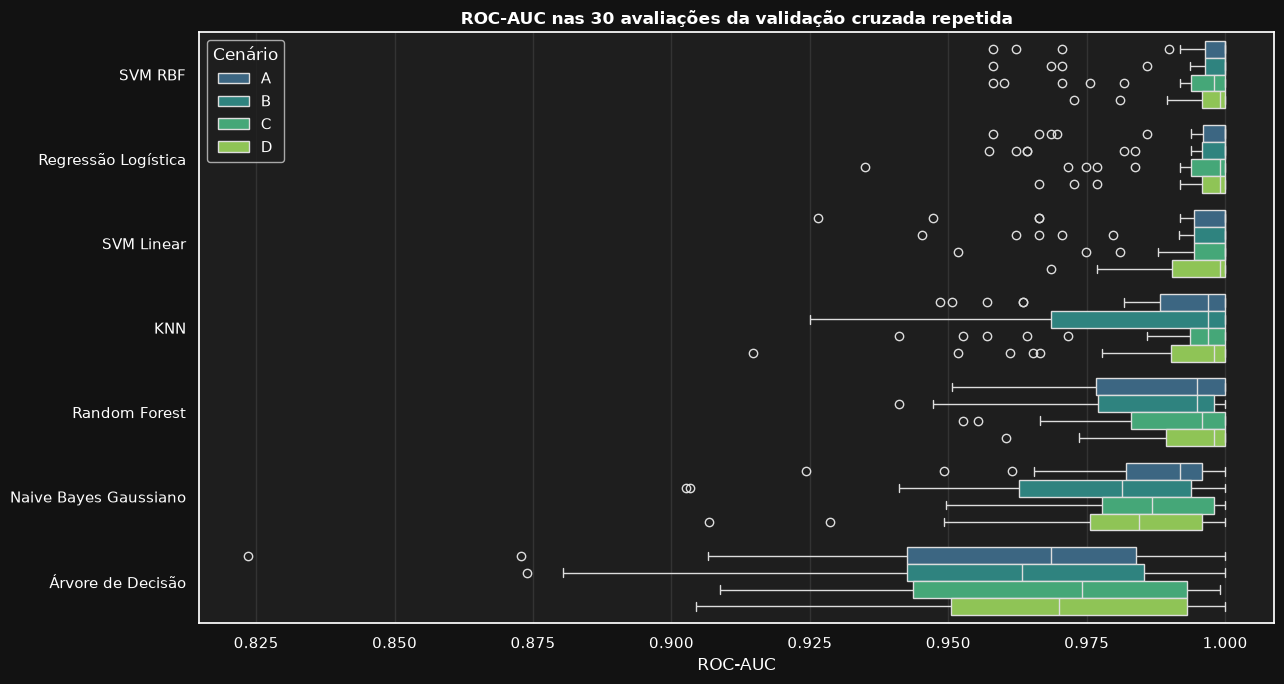

In [8]:
cv_repetida = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=2026)


def teste_t_pareado(a, b, razao_teste_treino=1 / 9):
    d = np.asarray(a) - np.asarray(b)
    n = len(d)
    if np.allclose(d, 0):
        return 0.0, 1.0, 1.0
    t = d.mean() / (d.std(ddof=1) / np.sqrt(n))
    t_corrigido = d.mean() / np.sqrt((1 / n + razao_teste_treino) * d.var(ddof=1))
    return d.mean(), 2 * stats.t.sf(abs(t), n - 1), 2 * stats.t.sf(abs(t_corrigido), n - 1)


def holm(p):
    """Ajuste de Holm-Bonferroni: controla a chance de pelo menos um falso positivo entre os m testes."""
    p = np.asarray(p, dtype=float)
    ordem = np.argsort(p)
    ajustado = np.empty_like(p)
    ajustado[ordem] = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[ordem]))
    return ajustado


repetida = {}
for chave, busca in buscas.items():
    r = cross_validate(busca.best_estimator_, X_train, y_train, cv=cv_repetida,
                       scoring={"ROC-AUC": "roc_auc", "Sensibilidade": "recall"}, n_jobs=-1)
    repetida[chave] = pd.DataFrame({"ROC-AUC": r["test_ROC-AUC"], "Sensibilidade": r["test_Sensibilidade"]})

linhas = []
for nome in MODELOS:
    for cenario in ["B", "C", "D"]:
        for metrica in ["ROC-AUC", "Sensibilidade"]:
            dif, p, p_corr = teste_t_pareado(repetida[(nome, cenario)][metrica], repetida[(nome, "A")][metrica])
            linhas.append({"modelo": nome, "comparação": f"{cenario} − A", "métrica": metrica,
                           "diferença": dif, "p_t_pareado": p, "p_corrigido": p_corr})
comparacoes = pd.DataFrame(linhas)
comparacoes["p_holm"] = comparacoes.groupby("métrica")["p_corrigido"].transform(holm)
cenarios_vs_a = comparacoes.pivot_table(index=["modelo", "comparação"], columns="métrica",
                                        values=["diferença", "p_corrigido", "p_holm"])
print("=== Cenários B, C e D contra o A, em cada modelo (30 avaliações; Holm nas 21 comparações de cada métrica) ===")
display(cenarios_vs_a.style.format("{:+.4f}", subset=["diferença"]).format("{:.4f}", subset=["p_corrigido", "p_holm"]))

media_repetida = pd.DataFrame({chave: r.mean() for chave, r in repetida.items()}).T
media_repetida.index.names = ["modelo", "cenário"]
melhor = media_repetida["ROC-AUC"].idxmax()
linhas = []
for chave in media_repetida.sort_values("ROC-AUC", ascending=False).index:
    dif, p, p_corr = teste_t_pareado(repetida[melhor]["ROC-AUC"], repetida[chave]["ROC-AUC"])
    linhas.append({"modelo": chave[0], "cenário": chave[1], "ROC-AUC": media_repetida.loc[chave, "ROC-AUC"],
                   "Sensibilidade": media_repetida.loc[chave, "Sensibilidade"],
                   "diferença_para_a_melhor": dif, "p_corrigido": p_corr})
ranking = pd.DataFrame(linhas).set_index(["modelo", "cenário"])
outras = np.array([chave != melhor for chave in ranking.index])
ranking["p_holm"] = np.nan
ranking.loc[outras, "p_holm"] = holm(ranking.loc[outras, "p_corrigido"])
ranking["difere_da_melhor"] = np.where(ranking["p_holm"] < 0.05, "sim", "não")
ranking.loc[~outras, "difere_da_melhor"] = "(melhor)"
print(f"\n=== Ranking pela ROC-AUC média (30 avaliações); melhor combinação: {melhor[0]}, cenário {melhor[1]} ===")
display(ranking.style.format({"ROC-AUC": "{:.4f}", "Sensibilidade": "{:.3f}", "diferença_para_a_melhor": "{:+.4f}",
                              "p_corrigido": "{:.4f}", "p_holm": "{:.4f}"}, na_rep="—"))

ordem = list(media_repetida.loc[(slice(None), "A"), "ROC-AUC"].sort_values(ascending=False).index.get_level_values(0))
dados_box = pd.concat([repetida[(n, c)].assign(modelo=n, cenário=c) for n in ordem for c in CENARIOS])
fig, ax = plt.subplots(figsize=(13, 7))
sns.boxplot(data=dados_box, x="ROC-AUC", y="modelo", hue="cenário", order=ordem,
            palette=sns.color_palette(PALETA, len(CENARIOS) + 1)[1:], linecolor="#dddddd", ax=ax)
ax.set_title("ROC-AUC nas 30 avaliações da validação cruzada repetida", color="white", fontweight="bold")
ax.set_ylabel("")
ax.legend(title="Cenário")
plt.tight_layout()
plt.show()

**Como interpretar:**
- **Reduzir a dimensão não muda significativamente o desempenho de nenhum modelo.** Nas 21 comparações de ROC-AUC com o cenário A, as diferenças ficam abaixo de 0,012 em valor absoluto, e nenhuma é significativa depois do ajuste de Holm (todos os p ajustados acima de 0,8).
- **Na sensibilidade, os efeitos que pareciam significativos somem com o ajuste.** Sem ajuste, o KNN melhoraria com PCA (+5,5 pontos, p corrigido = 0,006) e com seleção (+3,5 pontos, p = 0,017), o que combina com a ideia de que modelos de distância sofrem com muitas dimensões redundantes. Mas, entre 21 comparações, p-valores desse tamanho aparecem por acaso com alguma frequência, e com Holm eles passam a 0,13 e 0,33. É um indício a confirmar, não uma conclusão. A queda do Naive Bayes com PCA (−5,3 pontos) não é significativa nem sem ajuste (p corrigido = 0,078).
- **Ranking geral:** a melhor média é a do **SVM RBF no cenário D** (ROC-AUC de 0,9963), com a Regressão Logística D (0,9955) e o SVM RBF nos cenários B e A (0,9951 e 0,9949) logo atrás. **Nenhuma das outras 27 combinações difere significativamente da melhor** depois do ajuste de Holm. A Árvore de Decisão tem os menores valores nos quatro cenários (ROC-AUC de 0,956 a 0,968), com p de Nadeau e Bengio entre 0,005 e 0,009 antes do ajuste de Holm; o Naive Bayes nos cenários B, C e D também fica abaixo de 0,05 antes do ajuste (0,014 a 0,039). Isso sugere que esses modelos são de fato piores, mas a evidência não é suficiente quando se levam em conta as 27 comparações.
- **Leitura correta:** "não difere significativamente" não quer dizer "é igual". Com 455 pacientes e um teste conservador (Nadeau e Bengio com Holm), o poder para detectar diferenças de 0,01 na ROC-AUC é baixo. O que os dados mostram é que, na validação cruzada, não dá para separar os modelos do grupo de cima.

Na prática, o critério de desempate entre os modelos do topo deixa de ser a métrica e passa a ser simplicidade e interpretabilidade. Nisso, a **Regressão Logística no cenário D** se destaca: está em 2º no ranking (ROC-AUC de 0,9955 e sensibilidade de 0,945), tem otimismo desprezível na Seção 3.2 e usa só 10 atributos pouco correlacionados. Os coeficientes ficam mais fáceis de ler do que no cenário A, onde raio, perímetro e área entram juntos e os coeficientes ficam instáveis por causa da colinearidade.

## 5. Modelos salvos para a avaliação final

**Plano:** salvar os 28 pipelines ajustados no treino inteiro (pré-processamento + modelo, prontos para `predict` e `predict_proba`), a tabela de hiperparâmetros e os resultados da validação cruzada.

Todos os pipelines recebem os **30 atributos originais, sem padronizar**, com os nomes de coluna de `wdbc_limpo.csv`: o próprio pipeline padroniza e, conforme o cenário, aplica o PCA ou separa os atributos. Para avaliar no teste, basta recriar a mesma divisão e carregar os modelos:

```python
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/processed/wdbc_limpo.csv")
X, y = df.drop(columns=["id", "diagnosis"]), df["diagnosis"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

modelos = joblib.load("models/modelos_supervisionados.joblib")
modelo = modelos[("SVM RBF", "A")]            # chave: (nome do modelo, cenário)
probabilidade_maligno = modelo.predict_proba(X_test)[:, 1]
```

**Atenção:** não passar `X_test_scaled.csv`, `wdbc_test_pca.csv` nem `wdbc_test_top10.csv` para esses modelos. Esses arquivos já estão transformados, e o pipeline transformaria de novo (padronização dupla), o que dá previsões erradas sem nenhuma mensagem de erro. O `y_test.csv` de `Feature_selection.ipynb` tem os mesmos rótulos, na mesma ordem, que o `y_test` acima.

Os arquivos foram gerados com as versões impressas na Seção 0. Para carregar o `joblib`, é preciso ter a mesma versão do `scikit-learn` (ou rodar este notebook de novo).

In [9]:
pasta_modelos, pasta_resultados = BASE_DIR / "models", BASE_DIR / "results"
pasta_modelos.mkdir(exist_ok=True)
pasta_resultados.mkdir(exist_ok=True)

modelos_finais = {chave: busca.best_estimator_ for chave, busca in buscas.items()}
joblib.dump(modelos_finais, pasta_modelos / "modelos_supervisionados.joblib", compress=3)

exportar = resultados.copy()
exportar["melhores_hiperparametros"] = exportar["melhores_hiperparametros"].map(str)
exportar.to_csv(pasta_resultados / "hiperparametros_e_cv.csv")
ranking.to_csv(pasta_resultados / "ranking_cv_repetida.csv")

for arquivo in [pasta_modelos / "modelos_supervisionados.joblib", pasta_resultados / "hiperparametros_e_cv.csv",
                pasta_resultados / "ranking_cv_repetida.csv"]:
    print(f"{arquivo.relative_to(BASE_DIR)}  ({arquivo.stat().st_size / 1e6:.2f} MB)")

recarregados = joblib.load(pasta_modelos / "modelos_supervisionados.joblib")
assert len(recarregados) == len(MODELOS) * len(CENARIOS) and hasattr(recarregados[melhor], "predict_proba")
print("Modelos recarregados e conferidos:", len(recarregados))

models/modelos_supervisionados.joblib  (1.68 MB)
results/hiperparametros_e_cv.csv  (0.01 MB)
results/ranking_cv_repetida.csv  (0.00 MB)
Modelos recarregados e conferidos: 28


## Conclusões e recomendações para a avaliação final

**O que foi entregue:**
- `notebooks/modelagem_supervisionada.ipynb` (este notebook);
- `models/modelos_supervisionados.joblib`: os 28 pipelines (7 modelos × 4 cenários) ajustados no treino inteiro, com pré-processamento incluído e `predict_proba` disponível;
- `results/hiperparametros_e_cv.csv`: melhores hiperparâmetros e métricas da validação cruzada;
- `results/ranking_cv_repetida.csv`: ranking da validação cruzada repetida, com os p-valores corrigidos (Nadeau e Bengio) e ajustados (Holm).

**Principais resultados:**
1. Todos os classificadores separam muito bem tumores benignos e malignos (ROC-AUC de 0,96 a 0,997 na validação cruzada).
2. Regressão Logística, SVM Linear e SVM RBF formam o grupo de cima. A melhor média é a do SVM RBF com o Top-10 não redundante (cenário D), mas nenhuma das outras 27 combinações difere significativamente dela depois do ajuste para comparações múltiplas. A Árvore de Decisão tem os piores valores nos quatro cenários, também sem significância depois do ajuste.
3. Reduzir a dimensão (PCA, seleção pelo teste F ou Top-10 não redundante) não muda significativamente o desempenho de nenhum modelo. O Top-10 não redundante mantém o desempenho com só 10 atributos não redundantes, mas a lista varia entre folds e dá uma vantagem artificial à Árvore de Decisão e ao KNN na validação cruzada (Seção 3.2).

**Recomendações para a avaliação final:**
- **Avaliar no teste uma única vez**, com os modelos já escolhidos, sem voltar a ajustar nada depois de ver o resultado.
- **Entrada dos modelos:** os 30 atributos originais, sem padronizar (`wdbc_limpo.csv` com a mesma divisão, Seção 5). Não usar `X_test_scaled.csv` nem `wdbc_test_*.csv` com estes pipelines.
- Sugestão de modelos para destacar: **SVM RBF (A ou D)** pelo desempenho, **Regressão Logística (D)** como modelo interpretável com atributos não redundantes, e **Árvore de Decisão (A)** como referência interpretável simples. Na árvore, preferir o A, porque a vantagem do D na validação cruzada é quase toda otimismo.
- **Limiar para reduzir falsos negativos:** escolher o limiar com previsões fora da amostra no treino (`cross_val_predict(modelo, X_train, y_train, cv=..., method="predict_proba")`), e não no teste. Depois aplicar o limiar escolhido no teste. Com só 42 malignos no teste, cada falso negativo vale 2,4 pontos de sensibilidade, então vale reportar intervalos de confiança (bootstrap).